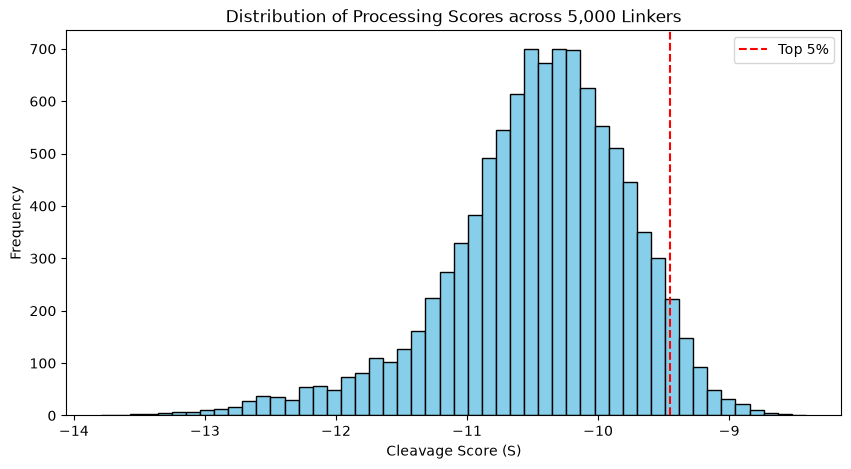

In [1]:
## Testing Discriminatory Power (The Histogram Test)

import pandas as pd
import matplotlib.pyplot as plt

# Load your scored doublets from the combinatorial step
#df = pd.read_csv("../results/Q76R36_scored_doublets.csv") # with first scoring function
#df = pd.read_csv("../results/Q76R36-1_scored_singlets.csv") # with last version of scoring funct 
df = pd.read_csv("../results/Q76R36-1_scored_doublets.csv")



plt.figure(figsize=(10, 5))
plt.hist(df['score'], bins=50, color='skyblue', edgecolor='black')
plt.title("Distribution of Processing Scores across 5,000 Linkers")
plt.xlabel("Cleavage Score (S)")
plt.ylabel("Frequency")
plt.axvline(df['score'].quantile(0.95), color='red', linestyle='dashed', label='Top 5%')
plt.legend()
plt.show()

In [10]:
df.loc[df['score'] >= df['score'].quantile(0.95)].head(15)

,seq_id,sequence,score
0,"doublet_6467|RRQW|E:9,L:4,E:9",LVVAASIIGRRQWDPLVVAASI,-8.413747
1,"doublet_2389|RHEW|E:9,L:4,E:9",DPLVVAASIRHEWLVVAASIIG,-8.547370
2,"doublet_6638|RIEW|E:9,L:4,E:9",LVVAASIIGRIEWDPLVVAASI,-8.559917
3,"doublet_1635|RIEW|E:9,L:4,E:9",DPLVVAASIRIEWLVVAASIIG,-8.646387
4,"doublet_9337|RMHW|E:9,L:4,E:9",LVVAASIIGRMHWDPLVVAASI,-8.666600
5,"doublet_9049|RDNW|E:9,L:4,E:9",LVVAASIIGRDNWDPLVVAASI,-8.701476
6,"doublet_4334|RMHW|E:9,L:4,E:9",DPLVVAASIRMHWLVVAASIIG,-8.709023
7,"doublet_253|KSEW|E:9,L:4,E:9",DPLVVAASIKSEWLVVAASIIG,-8.732394
8,"doublet_9926|RTTW|E:9,L:4,E:9",LVVAASIIGRTTWDPLVVAASI,-8.743642
9,"doublet_4923|RTTW|E:9,L:4,E:9",DPLVVAASIRTTWLVVAASIIG,-8.743783


In [4]:
df.loc[-df["sequence"].str.startswith("LVVA")]

,seq_id,sequence,score
1,construct1867|RHEW,DPLVVAASIRHEWLVVAASIIG,-8.547370
3,construct239|RIEW,DPLVVAASIRIEWLVVAASIIG,-8.646387
6,construct120|RMHW,DPLVVAASIRMHWLVVAASIIG,-8.709023
7,construct2714|KSEW,DPLVVAASIKSEWLVVAASIIG,-8.732394
9,construct3009|RTTW,DPLVVAASIRTTWLVVAASIIG,-8.743783
...,...,...,...
10001,construct3387|DGGN,DPLVVAASIDGGNLVVAASIIG,-13.445393
10002,construct3565|GQPT,DPLVVAASIGQPTLVVAASIIG,-13.495965
10003,construct840|EGEE,DPLVVAASIEGEELVVAASIIG,-13.559852
10004,construct3282|PGEE,DPLVVAASIPGEELVVAASIIG,-13.576825


In [13]:

q = df['score'].quantile(0.95)
top_df = df[df['score'] >= q].copy()
top_df['P1window'] = top_df['sequence'].str[9:9+8]
top_df

,seq_id,sequence,score,P1window
0,construct9125|RRQW,LVVAASIIGRRQWDPLVVAASI,-8.413747,RRQWDPLV
1,construct1867|RHEW,DPLVVAASIRHEWLVVAASIIG,-8.547370,RHEWLVVA
2,construct5242|RIEW,LVVAASIIGRIEWDPLVVAASI,-8.559917,RIEWDPLV
3,construct239|RIEW,DPLVVAASIRIEWLVVAASIIG,-8.646387,RIEWLVVA
4,construct5123|RMHW,LVVAASIIGRMHWDPLVVAASI,-8.666600,RMHWDPLV
...,...,...,...,...
496,construct8259|RWHF,LVVAASIIGRWHFDPLVVAASI,-9.443970,RWHFDPLV
497,construct2581|RKSF,DPLVVAASIRKSFLVVAASIIG,-9.444874,RKSFLVVA
498,construct9483|RSTQ,LVVAASIIGRSTQDPLVVAASI,-9.445710,RSTQDPLV
499,construct4633|QRWN,DPLVVAASIQRWNLVVAASIIG,-9.446753,QRWNLVVA


In [16]:
import logomaker

INFO: Loading scored sequences from ../results/Q76R36_scored_doublets.csv
Total sequences evaluated: 10006
Top 2% Score Threshold: S >= -9.2627
Number of elite linkers extracted: 201


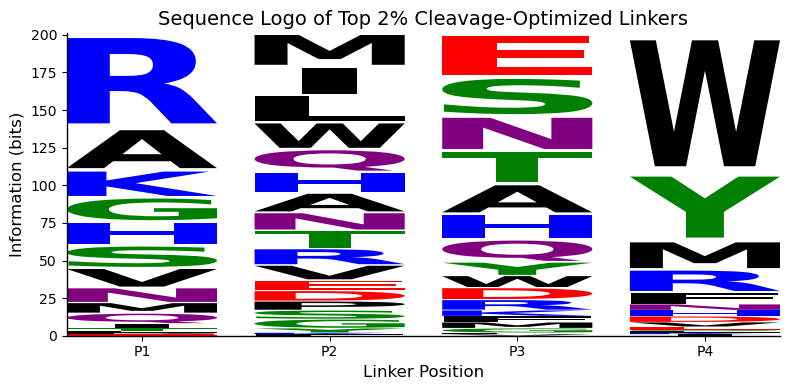

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import logomaker

def plot_top_linkers_logo(csv_file, epitope_len=9, linker_len=4, q = 0.95):
    print(f"INFO: Loading scored sequences from {csv_file}")
    df = pd.read_csv(csv_file)

    qid = str(round(100*(1.0-q)))
    # 1. Isolate the top q% highest scoring sequences
    q = df['score'].quantile(q)
    top_df = df[df['score'] >= q].copy()
    
    print(f"Total sequences evaluated: {len(df)}")
    print(f"Top {qid}% Score Threshold: S >= {q:.4f}")
    print(f"Number of elite linkers extracted: {len(top_df)}")
    
    # 2. Extract the Linker Sequences
    # Assuming E1(9) - L(4) - E2(9), the linker starts at index 9 and ends at 13
    start_idx = epitope_len
    end_idx = epitope_len + linker_len
    top_df['linker'] = top_df['sequence'].str[start_idx:end_idx]
    #top_df['P1window'] = top_df['sequence'].str[epitope_len:epitope_len+8]
    
    # 3. Create a Position Weight Matrix (PWM) for Logomaker
    # This aligns all the 4-mer linkers and calculates the frequency/information of each amino acid
    counts_mat = logomaker.alignment_to_matrix(top_df['linker'].tolist())
    
    # 4. Plot the Sequence Logo
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    
    # Using the 'chemistry' color scheme colors AAs by their biochemical properties
    logo = logomaker.Logo(counts_mat, 
                          ax=ax,
                          color_scheme='chemistry', 
                          vpad=.1, 
                          width=.8)
    
    # Styling
    logo.style_spines(visible=False)
    logo.style_spines(spines=['left', 'bottom'], visible=True)
    ax.set_ylabel("Information (bits)", fontsize=12)
    ax.set_xlabel("Linker Position", fontsize=12)
    
    # Label the x-axis properly (P1, P2, P3, P4)
    ax.set_xticks(range(linker_len))
    ax.set_xticklabels([f'P{i+1}' for i in range(linker_len)])
    
    ax.set_title(f"Sequence Logo of Top {qid}% Cleavage-Optimized Linkers", fontsize=14)
    
    plt.tight_layout()
    # plt.savefig("results/top_linkers_logo.png", dpi=300)
    plt.show()

# Run the function using your results file
plot_top_linkers_logo("../results/Q76R36_scored_doublets.csv",q=0.98)